# Aprendizaje evolutivo de la representación de los datos para modelos basados en distancias

Este notebook reúne todo el proceso que hemos seguido: la idea, la teoría que hay detrás, el código del método, los experimentos que hicimos (incluidos los que salieron mal) y la interpretación de cada gráfica. La idea es que se pueda leer de principio a fin y entender por qué hicimos cada cosa.

**Resumen de la aportación en cuatro líneas**

1. Aprendemos con CMA-ES una transformación por atributo (un exponente de Yeo-Johnson y un peso para cada atributo). Con eso se consigue una distancia ponderada que los modelos basados en distancias (KNN) usan mucho mejor que los datos originales.
2. Cambiamos la regla de predicción de KNN (media de los vecinos) a una regresión lineal local ponderada, y optimizamos la métrica directamente para esa regla.
3. Comprobamos que el algoritmo evolutivo concreto importa poco, que el PCA dentro de la búsqueda no aporta de forma consistente y que el método no mejora en Diabetes.
4. Con 12 datasets, el método mejora KNN un 25 % frente a los datos originales y es competitivo con Random Forest, Gradient Boosting y procesos gaussianos ajustados.

**Cómo está organizado**

| Sección | Contenido |
|---|---|
| 1 | El problema y el enunciado |
| 2 | Teoría: distancias, transformación, CMA-ES, fitness, regla local lineal y estado del arte |
| 3 | Código del método, comentado |
| 4 | Demostración en vivo con un presupuesto pequeño |
| 5 | Experimentos y resultados (leemos los CSV que guardaron los experimentos largos) |
| 6 | Análisis global, limitaciones y trabajo futuro |
| 7 | Referencias y cómo reproducir los experimentos |

**Nota sobre el tiempo de ejecución.** Los experimentos completos tardaron horas, así que aquí no se repiten. La sección 4 ejecuta el método en vivo con un presupuesto reducido (unos minutos en total) y la sección 5 lee los CSV con los resultados de los experimentos largos, que están en la carpeta `exploracion/` (y los del notebook principal en la raíz del proyecto).

## 1. El problema

El enunciado de la práctica pide un programa $P$ que, dado un conjunto de entrenamiento $(X_t, y_t)$, aprenda con técnicas de computación evolutiva una transformación de los atributos (síntesis de atributos o reducción de dimensionalidad). Esa transformación se aplica después al conjunto de validación, $X_v' = v(X_v)$.

El criterio de éxito es el siguiente. Si entrenamos un modelo arbitrario $M$ con los atributos originales y medimos el error absoluto medio (MAE) en validación, obtenemos $e$. Si entrenamos el mismo modelo $M$ con los atributos transformados y obtenemos $e'$, el método funciona cuando $e' < e$.

Hay que fijarse en tres cosas del planteamiento:

- El modelo $M$ es arbitrario. Por eso evaluamos siempre con varios modelos (regresión lineal, KNN y árbol de decisión) y no con uno solo.
- La transformación se aprende **solo con el entrenamiento**. La validación únicamente se usa para medir. Si la usáramos para guiar la búsqueda, el resultado no valdría nada.
- Lo que buscamos es que el método sea **generalizable**: que funcione igual en datasets distintos sin ajustes a mano.

**Datos.** Partimos de dos datasets de regresión: Diabetes (442 muestras, 10 atributos) y California Housing (20640 muestras, 8 atributos). Para comprobar que el método no es cosa de dos datasets, en la parte final usamos otros diez datasets de OpenML (la lista y sus tamaños están en la sección 5.1).

**Protocolo común.**

- Partición 70 % entrenamiento y 30 % validación, con semillas distintas para cada repetición.
- Métrica: MAE en validación.
- Para comparar entre datasets con escalas muy distintas usamos el MAE relativo a los datos originales, $\text{MAE}/\text{MAE}_{\text{crudo}}$, y lo promediamos con la media geométrica. Menor que 1 significa que mejoramos.
- Contrastes estadísticos con el test de Wilcoxon por pares, aplicado sobre el cociente de errores de cada pareja (dataset, partición).

## 2. Teoría

### 2.1 Por qué los modelos basados en distancias dependen tanto de la representación

KNN predice el valor de un punto nuevo promediando el valor de sus $k$ vecinos más cercanos. Lo que significa "cercano" lo define la distancia, normalmente la euclídea:

$$ d(\mathbf{x}, \mathbf{x}')^2 = \sum_{j=1}^{n} (x_j - x'_j)^2 $$

Esa fórmula trata todos los atributos igual, y eso es un problema por tres motivos:

- **Escala.** Si un atributo se mide en miles y otro en unidades, el primero domina la distancia aunque no sea el más informativo.
- **Atributos irrelevantes o ruidosos.** Cada atributo que no aporta información añade ruido a la distancia, y con muchos de ellos los vecinos dejan de ser los vecinos verdaderos (es la llamada maldición de la dimensionalidad).
- **Forma de la distribución.** Con atributos muy sesgados o con valores extremos, unos pocos puntos acaparan casi todo el rango y el resto queda comprimido.

Un árbol de decisión no sufre nada de esto, porque solo compara cada atributo con umbrales. Cualquier transformación monótona de un atributo no cambia el orden de los datos y, por tanto, no cambia el árbol. Lo usamos como control: si la transformación aprendida no cambia el error del árbol, es lo esperado y confirma que la mejora en KNN viene de la geometría y no de otra cosa.

### 2.2 La transformación que aprendemos

Para cada atributo $j$ aprendemos dos números, un exponente $\lambda_j$ y un peso $w_j$.

**Yeo-Johnson.** Es una familia de transformaciones de potencia que, a diferencia de Box-Cox, admite valores negativos y cero:

$$
\psi(x;\lambda) =
\begin{cases}
\dfrac{(x+1)^{\lambda}-1}{\lambda} & x \ge 0,\ \lambda \ne 0 \\[4pt]
\log(x+1) & x \ge 0,\ \lambda = 0 \\[4pt]
-\dfrac{(-x+1)^{2-\lambda}-1}{2-\lambda} & x < 0,\ \lambda \ne 2 \\[4pt]
-\log(-x+1) & x < 0,\ \lambda = 2
\end{cases}
$$

Con $\lambda = 1$ la transformación es la identidad. Con $\lambda < 1$ comprime los valores grandes (útil con colas largas a la derecha) y con $\lambda > 1$ los expande.

**Estandarización y peso.** Después de transformar, centramos y escalamos con la media $\mu_j$ y la desviación $\sigma_j$ del entrenamiento y multiplicamos por el peso:

$$ z_j = w_j \cdot \frac{\psi(x_j;\lambda_j) - \mu_j}{\sigma_j} $$

Con eso, la distancia euclídea en el espacio transformado es una **distancia ponderada** en el espacio original:

$$ d_\theta(\mathbf{x}, \mathbf{x}')^2 = \sum_{j} w_j^2 \left(\tilde{x}_j - \tilde{x}'_j\right)^2 $$

donde $\tilde{x}_j$ es el atributo transformado y estandarizado. El peso $w_j^2$ es la importancia del atributo $j$ en la distancia: si $w_j = 0$ el atributo desaparece, y si $w_j$ es grande domina. En términos de aprendizaje de métricas es una **métrica diagonal** (matriz de Mahalanobis diagonal) con un paso previo de transformación no lineal por atributo.

**Parámetros.** El vector que buscamos es $\theta = (\lambda_1, \dots, \lambda_n, w_1, \dots, w_n)$, con dimensión $2n$ (16 en California, 20 en Diabetes). Lo limitamos a $\lambda_j \in [-2, 2]$ y $w_j \in [0, 3]$.

**El punto de partida.** Con $\theta_0 = (1, \dots, 1)$ la transformación es exactamente la estandarización. Por eso la búsqueda arranca de la línea base "estándar", y cualquier mejora que encuentre es mejora real sobre ella. Esta propiedad la usamos siempre al diseñar los experimentos.

**Por qué limitamos $\lambda$.** Sin límites, el estimador de máxima verosimilitud de Yeo-Johnson dio $\lambda \approx 13.6$ para la longitud de California. Con ese valor la columna se colapsaba prácticamente en un solo valor. Con el rango $[-2, 2]$ eso no pasa.

### 2.3 CMA-ES

CMA-ES (Covariance Matrix Adaptation Evolution Strategy) es una estrategia evolutiva para optimización continua sin gradiente. Es la técnica evolutiva que usamos para buscar $\theta$.

Mantiene una distribución normal multivariante sobre el espacio de búsqueda, con media $\mathbf{m}$, tamaño de paso $\sigma$ y matriz de covarianza $\mathbf{C}$. En cada generación:

1. **Muestrea** $\lambda_{pop}$ candidatos: $\mathbf{x}_k \sim \mathbf{m} + \sigma\, \mathcal{N}(\mathbf{0}, \mathbf{C})$.
2. **Evalúa** el fitness de cada uno y los **ordena**.
3. **Selecciona** los $\mu$ mejores y recalcula la media como una media ponderada de ellos.
4. **Adapta** $\sigma$ (con un camino de evolución que mide si los pasos van todos en la misma dirección o se cancelan) y $\mathbf{C}$ (con una actualización de rango uno y otra de rango $\mu$) para que la distribución se alargue en las direcciones que funcionan.

Por qué nos conviene:

- **No necesita gradiente.** Nuestro fitness incluye vecinos más cercanos y ajustes locales, que no son derivables.
- **Solo usa el orden de los candidatos**, no su valor. Es invariante a transformaciones monótonas del fitness y bastante robusto al ruido.
- **Aprende la forma del problema** (qué parámetros están correlacionados o necesitan pasos distintos) con pocos parámetros propios. El tamaño de población por defecto es $\lambda_{pop} = 4 + \lfloor 3 \ln D \rfloor$.

**Implementación.** En el notebook principal de la práctica usamos una implementación propia. En los experimentos de esta extensión usamos la librería de referencia `cma` (Hansen), con la que obtuvimos resultados equivalentes. Trabajamos en el cubo normalizado $[0,1]^D$ y reescalamos a los límites de cada parámetro.

**Presupuesto.** Cada evaluación del fitness es lo más caro (validación cruzada con KNN o con el ajuste local). Usamos 1000 evaluaciones en los experimentos de la extensión y 2020 en el notebook principal. En todas las comparaciones, todos los métodos tienen el mismo presupuesto.

### 2.4 El fitness: cómo sabe la búsqueda que un $\theta$ es bueno

Para cada candidato $\theta$ medimos el error de un modelo sobre el entrenamiento usando validación cruzada de 5 pliegues. Pasos:

1. Subsample de hasta 2000 filas del entrenamiento (para que cada evaluación sea rápida).
2. Transformamos con $\theta$, con la media y la desviación calculadas sobre esas filas.
3. Para cada pliegue ajustamos el modelo y medimos el MAE en el pliegue de prueba.
4. Dividimos entre $s = \overline{|y - \text{mediana}(y)|}$, el error de un predictor trivial que siempre dice la mediana.

$$ f(\theta) = \frac{1}{5} \sum_{\text{pliegues}} \frac{\text{MAE}_{\text{pliegue}}(\theta)}{s} $$

El fitness es entonces una **fracción del error trivial**: 0.5 significa que el modelo comete la mitad de error que un predictor sin información. Esa normalización permite comparar datasets con escalas diferentes. En el notebook principal el fitness promedia regresión lineal y KNN. En la extensión usa el modelo para el que optimizamos (KNN o la regla local lineal).

**El riesgo: sobreajustar al fitness.** La búsqueda optimiza una estimación del error, no el error real. Con pocos datos (Diabetes tiene 309 muestras de entrenamiento) la búsqueda aprende el ruido de esos pliegues. Veremos que el fitness mejora y la validación no. Es el problema central de Diabetes.

### 2.5 La regla de predicción: de KNN a regresión lineal local

KNN es una regresión **local constante**: la predicción es la media de los $k$ vecinos. Funciona bien si la función es plana en el entorno, pero cuando hay pendiente comete un sesgo, sobre todo en los bordes de los datos.

La **regresión lineal local ponderada** ajusta, para cada punto de consulta $\mathbf{q}$, un hiperplano a sus vecinos y evalúa en $\mathbf{q}$. Para los $k$ vecinos $\mathbf{z}_i$ con valores $y_i$:

$$ \min_{\beta_0, \boldsymbol{\beta}} \ \sum_{i=1}^{k} \omega_i \big( y_i - \beta_0 - \boldsymbol{\beta}^{\top} (\mathbf{z}_i - \mathbf{q}) \big)^2 + r \, \bar{\omega}\, \lVert \boldsymbol{\beta} \rVert^2 $$

y la predicción es $\hat{y}(\mathbf{q}) = \beta_0$. Como centramos en $\mathbf{q}$, el término independiente es directamente la predicción.

- **Pesos de vecindad (tricúbicos):** $\omega_i = (1 - u_i^3)^3$ con $u_i = d_i / d_{\max}$, de modo que los vecinos lejanos pesan menos y el último pesa casi cero.
- **Ridge $r$:** estabiliza el ajuste cuando hay pocos vecinos o atributos muy correlacionados. No penalizamos el término independiente.
- **Parámetros de la regla:** $k$ y $r$. En el método final los aprende CMA-ES junto con $\theta$.

Es la idea clásica de la *locally weighted regression* (Atkeson, Moore y Schaal, 1997) y de la regresión polinómica local de la estadística no paramétrica. Lo que añadimos es optimizar la métrica de la distancia **directamente para esta regla**, en lugar de reutilizar la que era buena para KNN.

### 2.6 Qué hay en la literatura y dónde nos situamos

Es importante ser honestos sobre lo que no es nuevo:

- **Aprender métricas para KNN** es un campo establecido. LMNN y NCA se plantean para clasificación. Para regresión, Weinberger y Tesauro (2007) aprenden la métrica minimizando el error de regresión por kernel con gradiente, y existe una adaptación de LMNN a regresión con algoritmo evolutivo (2015).
- **Ponderar atributos con CMA-ES** también está publicado, para clasificación (2018).
- **Un ancho de banda por variable elegido por validación cruzada** (Hall, Li y Racine, 2007) es, en la práctica, una métrica diagonal optimizada para el estimador de regresión no paramétrica, y elimina de forma automática las variables irrelevantes.
- **Cambiar la regla de predicción** manteniendo una métrica fija lo hace DNNR (2022), que usa información diferencial de los vecinos.

Lo que no hemos encontrado publicado es la combinación concreta de (a) exponente de Yeo-Johnson y peso por atributo, (b) optimizada con CMA-ES, (c) directamente contra la regla local lineal, y (d) evaluada de forma sistemática frente a controles y a modelos de referencia. La búsqueda de bibliografía fue con un buscador general, no con Scopus o Google Académico, así que **la aportación honesta es un estudio empírico que combina técnicas conocidas, con ese punto posiblemente novedoso**, y no una técnica sin precedentes.

## 3. Código del método

Aquí está todo el código que necesita el método, comentado paso a paso. Los experimentos largos usan exactamente estas funciones (en los scripts de `exploracion/`).

### 3.1 Configuración y estilo de las gráficas

In [2]:
# Librerías que vamos a usar
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

from scipy.stats import yeojohnson, wilcoxon           # transformación y test estadístico
from sklearn.model_selection import train_test_split, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import cma                                               # CMA-ES (implementación de referencia)

warnings.filterwarnings("ignore")                        # quitamos avisos que no nos aportan

# Configuración general
SEMILLA        = 13                                      # semilla para la demostración
TAM_VALIDACION = 0.3                                     # 70 % entrenamiento, 30 % validación
N_SUBMUESTRA   = 2000                                    # filas que usa el fitness en cada evaluación
CARPETA_RES    = "exploracion"                           # carpeta con los CSV de los experimentos largos

# Estilo de las gráficas: fondo claro, rejilla suave y colores con significado fijo
# azules = líneas base, naranja = nuestro método, gris = controles y otros algoritmos
sup, tinta, tinta2, rejilla = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
naranja, gris = "#d9730d", "#9a9893"
azules = ["#cfe2f3", "#9cc3e4", "#5b9bd5", "#1f5fa8"]
plt.rcParams.update({
    "figure.facecolor": sup, "axes.facecolor": sup, "savefig.facecolor": sup,
    "axes.edgecolor": rejilla, "axes.labelcolor": tinta2,
    "xtick.color": tinta2, "ytick.color": tinta2,
    "text.color": tinta, "axes.titlecolor": tinta,
    "axes.grid": True, "grid.color": rejilla, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "normal",
    "legend.frameon": False, "figure.dpi": 100,
})

### 3.2 Carga de datos

Los dos datasets de la práctica están en `DATASETS/`. Los otros diez se descargan de OpenML la primera vez (después quedan guardados en la caché de scikit-learn). Nos quedamos solo con los atributos numéricos y, si un dataset tiene más de 10000 filas, usamos una submuestra fija de 10000 para que el coste sea comparable.

In [1]:
# Los dos datasets de la práctica: ruta del CSV y nombre de la columna objetivo
RUTAS = {
    "diabetes":   ("DATASETS/Diabetes.csv",   "target"),
    "california": ("DATASETS/California.csv", "MedHouseVal"),
}
# Los diez datasets adicionales de OpenML que usamos para comprobar que el método generaliza
DATASETS = ["diabetes", "california", "concrete_compressive_strength", "stock", "space_ga",
            "sulfur", "kin8nm", "bank8FM", "puma8NH", "house_8L", "cpu_small", "wine_quality"]

def cargar(nombre):
    # Devuelve los atributos X, el objetivo y y los nombres de los atributos
    if nombre in RUTAS:
        ruta, objetivo = RUTAS[nombre]
        df = pd.read_csv(ruta)
        return df.drop(columns=objetivo).values.astype(float), df[objetivo].values.astype(float), list(df.drop(columns=objetivo).columns)
    from sklearn.datasets import fetch_openml
    d = fetch_openml(name=nombre, as_frame=True, parser="auto")
    X = d.data.select_dtypes("number").dropna(axis=1).astype(float)   # solo atributos numéricos
    y = d.target.astype(float).values
    X = X.loc[:, X.nunique() > 1]                                      # quitamos columnas constantes
    nombres = list(X.columns); X = X.values
    if len(y) > 10000:                                                 # submuestra fija si el dataset es grande
        i = np.random.default_rng(0).choice(len(y), 10000, replace=False)
        X, y = X[i], y[i]
    return X, y, nombres

### 3.3 La transformación aprendida

`ajustar(Xt, theta)` recibe el entrenamiento y un vector $\theta = (\lambda, w)$ y devuelve una función `v` que transforma cualquier conjunto de datos. Lo importante es que **la media y la desviación se calculan solo con el entrenamiento** y se reutilizan para validación.

In [3]:
def ajustar(Xt, theta):
    # theta = (lambdas de Yeo-Johnson, pesos), cada uno con n valores (n = nº de atributos)
    n = Xt.shape[1]
    lam, w = theta[:n], theta[n:2 * n]
    # 1) Yeo-Johnson por atributo con el exponente que propone la búsqueda
    C = np.column_stack([yeojohnson(Xt[:, j], lmbda=lam[j]) for j in range(n)])
    # 2) Media y desviación del entrenamiento (si una columna es constante, dividimos entre 1)
    mu, sd = C.mean(0), C.std(0)
    sd[sd == 0] = 1.0
    def v(X):
        # Aplicamos lo mismo a cualquier conjunto: transformar, estandarizar y ponderar
        Z = np.column_stack([yeojohnson(X[:, j], lmbda=lam[j]) for j in range(n)])
        return w * (Z - mu) / sd
    return v

def estandar(Xt):
    # Línea base "estándar": equivale a ajustar(Xt, theta0) con theta0 = (1, ..., 1)
    mu, sd = Xt.mean(0), Xt.std(0)
    sd[sd == 0] = 1.0
    return lambda X: (X - mu) / sd

### 3.4 Reglas de predicción: KNN y regresión lineal local

Las dos funciones están escritas con operaciones de NumPy por bloques para que sean rápidas, porque el fitness las llama miles de veces. `knn_rapido` da el mismo resultado que `KNeighborsRegressor` (salvo empates entre distancias iguales) y `llr` es la regresión lineal local de la sección 2.5.

In [4]:
def knn_rapido(Za, ya, Zb, k):
    # KNN por fuerza bruta: predice Zb usando como referencia (Za, ya)
    # d(b, a)^2 = |b|^2 + |a|^2 - 2 b.a, calculado para todas las parejas a la vez
    d = (Zb ** 2).sum(1)[:, None] + (Za ** 2).sum(1)[None, :] - 2 * Zb @ Za.T
    idx = np.argpartition(d, k - 1, axis=1)[:, :k]          # índices de los k vecinos de cada punto
    return ya[idx].mean(1)                                    # media de sus valores objetivo

def llr(Za, ya, Zb, k, ridge, trozo=300):
    # Regresión lineal local ponderada: un ajuste lineal con los k vecinos de cada punto de consulta
    k = min(k, len(Za))
    na = (Za ** 2).sum(1)
    salida = np.empty(len(Zb))
    for i in range(0, len(Zb), trozo):                        # procesamos por trozos para no gastar memoria
        zb = Zb[i:i + trozo]
        d2 = (zb ** 2).sum(1)[:, None] + na[None, :] - 2 * zb @ Za.T
        idx = np.argpartition(d2, k - 1, axis=1)[:, :k]       # vecinos de cada consulta
        dk = np.maximum(np.take_along_axis(d2, idx, 1), 0)    # sus distancias al cuadrado
        # pesos tricúbicos: los vecinos más lejanos pesan menos (el último casi 0)
        u = np.sqrt(dk / (dk.max(1, keepdims=True) + 1e-12))
        w = (1 - u ** 3) ** 3 + 1e-3
        # diseño local: columna de unos (término independiente) y diferencias respecto a la consulta
        Dz = Za[idx] - zb[:, None, :]
        A = np.concatenate([np.ones(Dz.shape[:2] + (1,)), Dz], axis=2)
        Aw = A * w[..., None]
        M = np.einsum("qki,qkj->qij", Aw, A)                  # A' W A para cada consulta
        reg = ridge * w.sum(1)[:, None, None] * np.eye(A.shape[2])[None]
        reg[:, 0, 0] = 0                                       # no penalizamos el término independiente
        b = np.einsum("qki,qk->qi", Aw, ya[idx])              # A' W y
        try:
            sol = np.linalg.solve(M + reg + 1e-9 * np.eye(A.shape[2]), b[..., None])[:, 0, 0]
        except np.linalg.LinAlgError:                          # si algún sistema es singular, caemos a la media
            sol = ya[idx].mean(1)
        salida[i:i + trozo] = sol                              # la predicción es el término independiente
    return salida

### 3.5 El fitness

Cada función `hacer_fitness_*` devuelve una función `f(theta)` que se puede pasar a cualquier optimizador. Los pliegues de validación cruzada se fijan una vez (con la semilla), de modo que todos los candidatos se evalúan sobre los mismos pliegues y la comparación entre ellos es justa.

In [5]:
def hacer_fitness_knn(Xs, ys, semilla, k=5):
    # Fitness para optimizar la métrica con KNN: MAE de validación cruzada / error del predictor trivial
    escala = np.mean(np.abs(ys - np.median(ys)))                          # error si siempre predecimos la mediana
    pliegues = list(KFold(5, shuffle=True, random_state=semilla).split(Xs))  # pliegues fijos
    def f(theta):
        try:
            Z = ajustar(Xs, np.asarray(theta, float))(Xs)                 # transformamos con este theta
            err = [np.mean(np.abs(knn_rapido(Z[a], ys[a], Z[b], k) - ys[b])) for a, b in pliegues]
            r = np.mean(err) / escala
            return r if np.isfinite(r) else 1e6                           # penalizamos casos numéricamente rotos
        except Exception:
            return 1e6
    return f

def hacer_fitness_llr(Xs, ys, semilla, n):
    # Fitness para optimizar la métrica Y los parámetros de la regla local lineal a la vez
    # theta = (lambdas[n], pesos[n], log k, log ridge)
    escala = np.mean(np.abs(ys - np.median(ys)))
    pliegues = list(KFold(5, shuffle=True, random_state=semilla).split(Xs))
    def f(theta):
        try:
            k = int(round(np.exp(theta[2 * n])))                          # número de vecinos
            ridge = np.exp(theta[2 * n + 1])                              # regularización
            Z = ajustar(Xs, theta[:2 * n])(Xs)
            err = [np.mean(np.abs(llr(Z[a], ys[a], Z[b], k, ridge) - ys[b])) for a, b in pliegues]
            r = np.mean(err) / escala
            return r if np.isfinite(r) else 1e6
        except Exception:
            return 1e6
    return f

### 3.6 La búsqueda con CMA-ES

`buscar_cma` envuelve la librería `cma`. Trabajamos en el cubo $[0,1]^D$ y reescalamos a los límites reales de cada parámetro, y guardamos el mejor fitness hallado tras cada evaluación para poder dibujar la curva de convergencia. La búsqueda arranca en $\theta_0 = (1, \dots, 1)$ (la estandarización), con un paso inicial $\sigma_0 = 0.2$ (un 20 % del rango).

In [6]:
def limites(n):
    # Límites de theta: lambdas en [-2, 2], pesos en [0, 3]; punto de partida theta0 = (1, ..., 1)
    lo = np.r_[np.full(n, -2.0), np.zeros(n)]
    hi = np.r_[np.full(n, 2.0), np.full(n, 3.0)]
    x0 = np.ones(2 * n)
    return x0, lo, hi

def buscar_cma(f, x0, lo, hi, semilla, presupuesto, sigma0=0.2):
    # Optimiza f con CMA-ES dentro de los límites [lo, hi] con 'presupuesto' evaluaciones
    historial = []                                           # mejor fitness encontrado tras cada evaluación
    mejor = [np.inf]
    def g(u):
        v = f(lo + np.clip(u, 0, 1) * (hi - lo))             # de cubo [0,1] a espacio real
        mejor[0] = min(mejor[0], v)
        historial.append(mejor[0])
        return v
    u0 = (np.asarray(x0, float) - lo) / (hi - lo)
    opciones = dict(seed=semilla + 1, bounds=[0, 1], maxfevals=presupuesto, verbose=-9)
    res = cma.fmin(g, u0, sigma0, options=opciones)
    theta = lo + np.clip(res[0], 0, 1) * (hi - lo)
    return theta, res[1], historial

### 3.7 Elegir $k$ y la regularización sin usar la validación

En las configuraciones que **no** aprenden esos parámetros con CMA-ES (las líneas base), los elegimos por validación cruzada dentro del entrenamiento, de modo que la comparación sea justa.

In [7]:
def elegir_k_knn(Zs, ys, semilla, kmax=30):
    # k de KNN por validación cruzada sobre la submuestra de entrenamiento
    pliegues = list(KFold(5, shuffle=True, random_state=semilla).split(Zs))
    cv = {k: np.mean([np.mean(np.abs(knn_rapido(Zs[a], ys[a], Zs[b], k) - ys[b])) for a, b in pliegues])
          for k in range(1, kmax + 1)}
    return min(cv, key=cv.get)

def elegir_k_ridge_llr(Zs, ys, semilla, n):
    # (k, ridge) de la regla local lineal por validación cruzada en una rejilla pequeña de 15 combinaciones
    pliegues = list(KFold(5, shuffle=True, random_state=semilla).split(Zs))
    mejor, elegido = np.inf, None
    for k in sorted({n + 3, 15, 25, 40, 80}):                # k siempre mayor que el nº de parámetros locales
        for ridge in (0.01, 0.1, 1.0):
            v = np.mean([np.mean(np.abs(llr(Zs[a], ys[a], Zs[b], k, ridge) - ys[b])) for a, b in pliegues])
            if v < mejor:
                mejor, elegido = v, (k, ridge)
    return elegido

def mae(pred, real):
    return float(np.mean(np.abs(pred - real)))

## 4. Demostración en vivo

Ejecutamos el método completo sobre una partición de cada dataset de la práctica, con un presupuesto reducido (`PRESUPUESTO_DEMO` evaluaciones en lugar de las 1000 de los experimentos), para ver cada paso funcionando. Los números exactos no coincidirán con los de la sección 5, que promedian muchas particiones, pero la tendencia sí.

En cada dataset calculamos:

| Configuración | Qué es |
|---|---|
| crudo + KNN | $e$ del enunciado: KNN con los atributos originales |
| estándar + KNN | línea base: atributos estandarizados, $k$ por validación cruzada |
| estándar + LLR | regla local lineal con los atributos estandarizados |
| métrica(KNN) + KNN | métrica aprendida con CMA-ES para KNN |
| métrica(KNN) + LLR | la misma métrica, con la regla local lineal |
| métrica(LLR) + LLR | método completo: métrica, $k$ y ridge optimizados para la regla local lineal |

In [8]:
PRESUPUESTO_DEMO = 400      # evaluaciones del fitness por búsqueda (en los experimentos largos son 1000)

def demo(nombre, semilla=SEMILLA, presupuesto=PRESUPUESTO_DEMO):
    X, y, nombres = cargar(nombre)
    Xt, Xv, yt, yv = train_test_split(X, y, test_size=TAM_VALIDACION, random_state=semilla)
    n = X.shape[1]
    # submuestra del entrenamiento sobre la que se calcula el fitness (la validación no se toca)
    sub = np.random.default_rng(semilla).choice(len(yt), min(N_SUBMUESTRA, len(yt)), replace=False)
    Xs, ys = Xt[sub], yt[sub]
    res, tiempos = {}, {}

    # 1) línea base del enunciado: KNN con k = 5 sobre los atributos originales
    res["crudo + KNN"] = mae(KNeighborsRegressor(5).fit(Xt, yt).predict(Xv), yv)

    # 2) estándar: estandarizamos con el entrenamiento; k de KNN y (k, ridge) de la regla local por validación cruzada
    est = estandar(Xt)
    k = elegir_k_knn(est(Xs), ys, semilla)
    res["estándar + KNN"] = mae(KNeighborsRegressor(k).fit(est(Xt), yt).predict(est(Xv)), yv)
    k2, r2 = elegir_k_ridge_llr(est(Xs), ys, semilla, n)
    res["estándar + LLR"] = mae(llr(est(Xt), yt, est(Xv), k2, r2), yv)

    # 3) métrica aprendida con CMA-ES para KNN
    x0, lo, hi = limites(n)
    t0 = time.time()
    theta, fit_final, hist = buscar_cma(hacer_fitness_knn(Xs, ys, semilla), x0, lo, hi, semilla, presupuesto)
    tiempos["métrica(KNN)"] = time.time() - t0
    v = ajustar(Xt, theta)
    k = elegir_k_knn(v(Xs), ys, semilla)
    res["métrica(KNN) + KNN"] = mae(KNeighborsRegressor(k).fit(v(Xt), yt).predict(v(Xv)), yv)
    k2, r2 = elegir_k_ridge_llr(v(Xs), ys, semilla, n)
    res["métrica(KNN) + LLR"] = mae(llr(v(Xt), yt, v(Xv), k2, r2), yv)

    # 4) método completo: la búsqueda optimiza la métrica, k y ridge para la regla local lineal
    kmin = n + 3
    x0l = np.r_[x0, np.log(max(kmin, 10)), np.log(0.1)]
    lol = np.r_[lo, np.log(kmin), np.log(1e-3)]
    hil = np.r_[hi, np.log(80), np.log(10.0)]
    t0 = time.time()
    thl, fit_l, hist_l = buscar_cma(hacer_fitness_llr(Xs, ys, semilla, n), x0l, lol, hil, semilla, presupuesto)
    tiempos["métrica(LLR)"] = time.time() - t0
    vl = ajustar(Xt, thl[:2 * n])
    res["métrica(LLR) + LLR"] = mae(llr(vl(Xt), yt, vl(Xv), int(round(np.exp(thl[2 * n]))), float(np.exp(thl[2 * n + 1]))), yv)

    return dict(nombre=nombre, nombres=nombres, res=res, theta=theta, hist=hist, theta_llr=thl, hist_llr=hist_l,
                fitness0=hist[0], tiempos=tiempos, n=n)

demos = {}
for nombre in ["diabetes", "california"]:
    t0 = time.time()
    demos[nombre] = demo(nombre)
    print(f"{nombre}: demostración terminada en {time.time() - t0:.0f} s")

diabetes: demostración terminada en 4 s


california: demostración terminada en 56 s


In [9]:
# Tabla de resultados de la demostración: MAE y cambio relativo respecto a los datos originales
filas = []
for nombre, d in demos.items():
    crudo = d["res"]["crudo + KNN"]
    for metodo, valor in d["res"].items():
        filas.append(dict(dataset=nombre, configuración=metodo, MAE=round(valor, 4), cambio_vs_crudo=f"{100 * (valor / crudo - 1):+.1f} %"))
tabla_demo = pd.DataFrame(filas)
display(tabla_demo.pivot(index="configuración", columns="dataset", values="cambio_vs_crudo").loc[list(demos["diabetes"]["res"])])

dataset,california,diabetes
configuración,,
crudo + KNN,+0.0 %,+0.0 %
estándar + KNN,-45.8 %,-1.3 %
estándar + LLR,-49.7 %,+1.5 %
métrica(KNN) + KNN,-58.5 %,+5.4 %
métrica(KNN) + LLR,-59.7 %,+1.2 %
métrica(LLR) + LLR,-60.6 %,+3.4 %


**Cómo leer la tabla.** Cada celda es el cambio del MAE respecto a KNN con los atributos originales (la referencia $e$ del enunciado). Un valor negativo significa $e' < e$, o sea, que mejoramos.

**Qué esperamos ver.** En California la transformación aprendida debe mejorar mucho a KNN, porque los atributos tienen escalas y colas muy distintas, y la regla local lineal debe mejorar un poco más. En Diabetes los cambios son pequeños y pueden ser de cualquier signo: tiene pocos datos y todos los atributos están ya en una escala parecida, así que hay poco margen y mucho ruido. Con una sola partición no se puede concluir nada sobre Diabetes (eso lo veremos con 10 particiones en la sección 5).

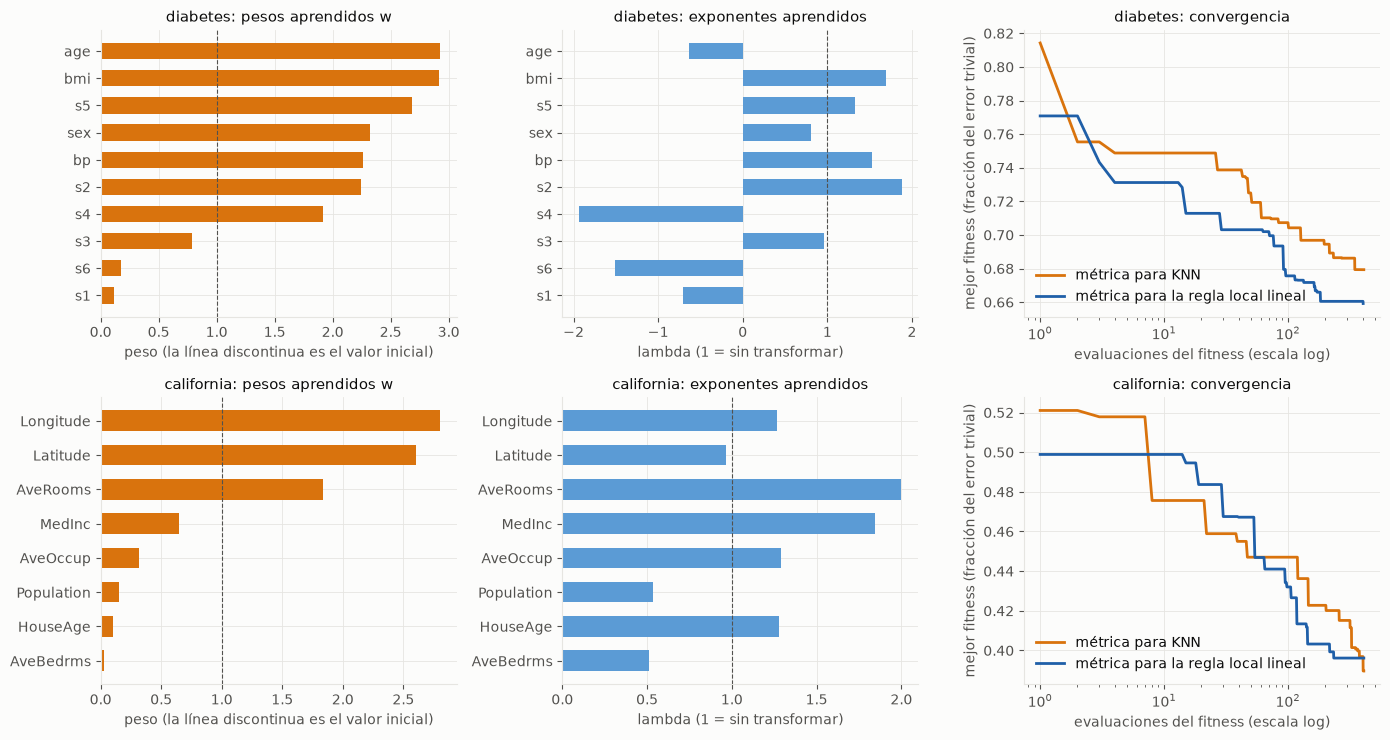

In [10]:
# Figura 1: qué ha aprendido la búsqueda (exponentes y pesos por atributo) y cómo converge
fig, ejes = plt.subplots(2, 3, figsize=(14, 7.5))
for i, (nombre, d) in enumerate(demos.items()):
    n, nom, th = d["n"], d["nombres"], d["theta"]
    # (a) pesos aprendidos: cuánto pesa cada atributo en la distancia
    orden = np.argsort(th[n:2 * n])
    ejes[i, 0].barh([nom[j] for j in orden], th[n:2 * n][orden], color=naranja, height=0.6)
    ejes[i, 0].axvline(1, color=tinta2, lw=0.8, ls="--")                 # peso 1 = estandarización
    ejes[i, 0].set_title(f"{nombre}: pesos aprendidos w")
    ejes[i, 0].set_xlabel("peso (la línea discontinua es el valor inicial)")
    # (b) exponentes de Yeo-Johnson aprendidos
    ejes[i, 1].barh([nom[j] for j in orden], th[:n][orden], color=azules[2], height=0.6)
    ejes[i, 1].axvline(1, color=tinta2, lw=0.8, ls="--")                 # lambda 1 = identidad
    ejes[i, 1].set_title(f"{nombre}: exponentes aprendidos")
    ejes[i, 1].set_xlabel("lambda (1 = sin transformar)")
    # (c) convergencia: mejor fitness encontrado a medida que gastamos evaluaciones
    ejes[i, 2].plot(np.arange(1, len(d["hist"]) + 1), d["hist"], color=naranja, lw=2, label="métrica para KNN")
    ejes[i, 2].plot(np.arange(1, len(d["hist_llr"]) + 1), d["hist_llr"], color=azules[3], lw=2, label="métrica para la regla local lineal")
    ejes[i, 2].set_xscale("log")
    ejes[i, 2].set_title(f"{nombre}: convergencia")
    ejes[i, 2].set_xlabel("evaluaciones del fitness (escala log)")
    ejes[i, 2].set_ylabel("mejor fitness (fracción del error trivial)")
    ejes[i, 2].legend(loc="lower left")
fig.tight_layout()
plt.show()

**Cómo interpretar la figura.**

- **Pesos (columna izquierda).** Un peso por encima de 1 significa que el atributo cuenta más que en la estandarización y un peso cercano a 0 que casi se ignora. Mirad si los atributos que más pesan tienen sentido en el dominio. En California deberían destacar la latitud y la longitud, porque el precio de una casa depende sobre todo de dónde está, y es lo que encontramos en el experimento principal.
- **Exponentes (columna central).** Un valor lejos de 1 indica que la búsqueda ha decidido deformar ese atributo (por ejemplo comprimir una cola larga). Los atributos con $\lambda$ cercano a 1 se quedan prácticamente como estaban.
- **Convergencia (columna derecha).** La curva siempre es no creciente porque guarda el mejor valor hasta ese momento. Empieza en el fitness de $\theta_0$, que es el de la línea base estándar, así que **la distancia entre el inicio y el final de la curva es la mejora que logra la búsqueda sobre el entrenamiento**. Una curva que sigue bajando al final indica que más presupuesto podría ayudar, y una curva plana desde pronto indica que la búsqueda se ha estancado.
- **Cuidado con Diabetes.** Que el fitness baje no garantiza que baje el error de validación. Es lo que se ve en la sección 5.7.

## 5. Experimentos y resultados

Cada experimento se hizo con un script en `exploracion/` que guardó sus resultados en un CSV. Aquí los leemos, resumimos y dibujamos. Seguimos el orden en que fuimos haciéndolos, porque cada uno nació de lo que dejó abierto el anterior.

Dos utilidades que usaremos en todas las secciones: una función para el contraste por pares y otra para leer los CSV.

In [11]:
def leer(nombre):
    # Lee un CSV de la carpeta de resultados de la extensión
    return pd.read_csv(os.path.join(CARPETA_RES, nombre))

def contraste(q, a, b):
    # Compara el método a con el b sobre las mismas parejas (dataset, partición).
    # q es una tabla con una fila por pareja y una columna por método (valores = MAE).
    # Usamos el cociente de errores: x < 0 significa que a comete menos error que b.
    x = np.log(q[a] / q[b])
    return dict(cambio_pct=100 * (np.exp(x.mean()) - 1),        # media geométrica del cociente, en %
                mejor_en=f"{int((x < 0).sum())}/{len(x)}",       # en cuántas parejas gana a
                p_wilcoxon=wilcoxon(x).pvalue)

### 5.0 El punto de partida: CMA-ES sobre Diabetes y California (notebook principal)

El primer experimento es el del notebook principal de la práctica. Aprendimos $\theta$ con CMA-ES (fitness: media de regresión lineal y KNN, 2020 evaluaciones) en 13 particiones de cada uno de los dos datasets. Aquí recalculamos los errores de los datos originales (los $e$ del enunciado) y los comparamos con los de CMA-ES, que leemos del CSV guardado.

In [12]:
# Errores con los atributos originales en las 13 particiones del notebook principal (semillas 13 a 25)
modelos = {"Regresión Lineal": lambda: LinearRegression(),
           "KNN": lambda: KNeighborsRegressor(),
           "Árbol de decisión": lambda: DecisionTreeRegressor(random_state=13)}
principal = pd.read_csv("resultados_cmaes.csv")                    # resultados de CMA-ES del notebook principal
filas = []
for nombre in ["diabetes", "california"]:
    X, y, _ = cargar(nombre)
    for s in range(13, 26):
        Xt, Xv, yt, yv = train_test_split(X, y, test_size=TAM_VALIDACION, random_state=s)
        for m, fabrica in modelos.items():
            e = mae(fabrica().fit(Xt, yt).predict(Xv), yv)         # error con atributos originales
            e_nuevo = principal[(principal.dataset == nombre) & (principal.semilla == s)][m].iloc[0]
            filas.append(dict(dataset=nombre, semilla=s, modelo=m, e=e, e_prima=e_nuevo))
punto_partida = pd.DataFrame(filas)
punto_partida["cambio_pct"] = 100 * (punto_partida.e_prima / punto_partida.e - 1)

resumen = []
for (nombre, m), g in punto_partida.groupby(["dataset", "modelo"]):
    x = np.log(g.e_prima / g.e)
    resumen.append(dict(dataset=nombre, modelo=m, e=round(g.e.mean(), 3), e_prima=round(g.e_prima.mean(), 3),
                        cambio_pct=round(g.cambio_pct.mean(), 1), mejora_en=f"{int((x < 0).sum())}/13",
                        p_wilcoxon=round(wilcoxon(x).pvalue, 4)))
display(pd.DataFrame(resumen))

,dataset,modelo,e,e_prima,cambio_pct,mejora_en,p_wilcoxon
0,california,KNN,0.826,0.299,-63.8,13/13,0.0002
1,california,Regresión Lineal,0.533,0.486,-8.7,13/13,0.0002
2,california,Árbol de decisión,0.463,0.462,-0.2,11/13,0.0134
3,diabetes,KNN,47.100,48.183,2.5,4/13,0.1677
4,diabetes,Regresión Lineal,44.904,45.011,0.2,4/13,0.0681
5,diabetes,Árbol de decisión,61.948,62.510,0.9,7/13,0.8926


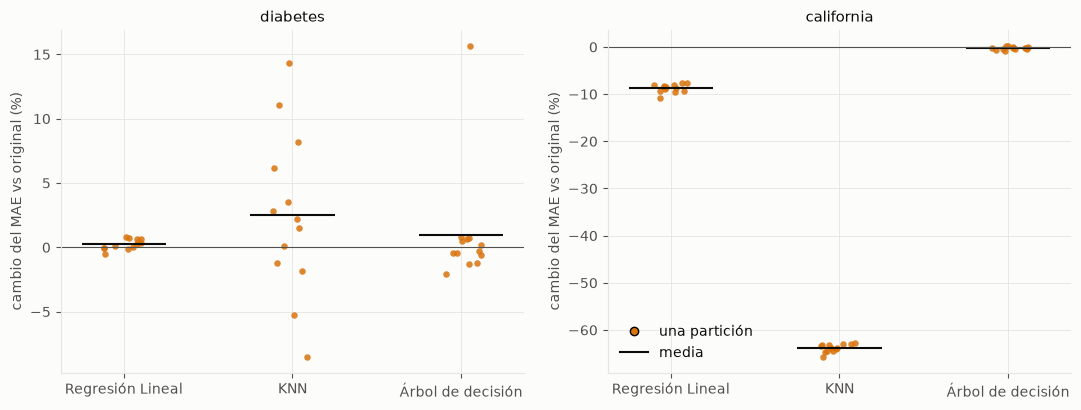

In [13]:
# Figura 2: cambio del MAE por partición respecto a los atributos originales (negativo = mejora)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
rng = np.random.default_rng(0)
for ax, nombre in zip(ejes, ["diabetes", "california"]):
    for j, m in enumerate(modelos):
        c = punto_partida[(punto_partida.dataset == nombre) & (punto_partida.modelo == m)].cambio_pct.values
        ax.scatter(j + rng.uniform(-0.12, 0.12, len(c)), c, s=22, color=naranja, alpha=0.85, linewidths=0)
        ax.hlines(c.mean(), j - 0.25, j + 0.25, color=tinta, lw=1.5)
    ax.axhline(0, color=tinta2, lw=0.8)
    ax.set_xticks(range(3)); ax.set_xticklabels(list(modelos)); ax.set_title(nombre)
    ax.set_ylabel("cambio del MAE vs original (%)")
ejes[-1].legend(handles=[Line2D([0], [0], marker="o", color="none", markerfacecolor=naranja, label="una partición"),
                         Line2D([0], [0], color=tinta, lw=1.5, label="media")], loc="best")
fig.tight_layout(); plt.show()

**Cómo interpretar la figura.** Cada punto es una partición y la raya negra es la media. Los puntos por debajo de cero son mejoras. Lo que interesa mirar es la **dispersión**: si todos los puntos están en el mismo lado de cero, la mejora es consistente. Si están repartidos a ambos lados, la media no significa nada.

**Qué vemos.**

- **California:** KNN mejora muchísimo (alrededor de un 64 %) y Regresión Lineal un 9 %, en las 13 particiones. El árbol no cambia, como esperábamos.
- **Diabetes:** los puntos están a ambos lados de cero y las medias son prácticamente 0 o ligeramente positivas. En este dataset el método no cumple $e' < e$.

Con este resultado nacieron las preguntas de las secciones siguientes: ¿importa el algoritmo evolutivo?, ¿qué pasa en otros datasets?, ¿se puede mejorar la representación o la regla de predicción?

### 5.1 Los datasets

Antes de generalizar, conviene ver con qué datos trabajamos. La tabla muestra el número de muestras y de atributos de cada dataset (después de quedarnos con los numéricos y de limitar a 10000 filas).

In [14]:
# Tamaño de cada dataset (si no hay conexión y alguno no está en la caché, se deja vacío)
filas = []
for nombre in DATASETS:
    try:
        X, y, _ = cargar(nombre)
        filas.append(dict(dataset=nombre, muestras=X.shape[0], atributos=X.shape[1], origen="práctica" if nombre in RUTAS else "OpenML"))
    except Exception as e:
        filas.append(dict(dataset=nombre, muestras=None, atributos=None, origen="no disponible"))
display(pd.DataFrame(filas))

,dataset,muestras,atributos,origen
0,diabetes,442,10,práctica
1,california,20640,8,práctica
2,concrete_compressive_strength,1030,8,OpenML
3,stock,950,9,OpenML
4,space_ga,3107,6,OpenML
5,sulfur,10000,6,OpenML
6,kin8nm,8192,8,OpenML
7,bank8FM,8192,8,OpenML
8,puma8NH,8192,8,OpenML
9,house_8L,10000,8,OpenML


Son datasets pequeños o medianos, con entre 6 y 12 atributos numéricos, y los hemos elegido porque son de regresión, tienen tamaños manejables y están disponibles en OpenML. **No están elegidos para que el método gane**, pero sí los escogí yo entre los que había, así que la muestra no es aleatoria y hay que tenerlo en cuenta al generalizar.

### 5.2 ¿Importa el algoritmo evolutivo? Comparación de técnicas bioinspiradas

El PDF de referencia (Fister et al., 2013) clasifica los algoritmos inspirados en la naturaleza en cuatro familias: enjambres, bioinspirados no basados en enjambre, físicos o químicos y otros. Quisimos ver si había otra técnica mejor que CMA-ES para este problema.

**Diseño del test.**

- Los mismos 20 y 16 parámetros ($\theta$), el mismo fitness (media de regresión lineal y KNN, como en el notebook principal) y el mismo presupuesto de 1000 evaluaciones para todos.
- 20 algoritmos, casi todos de la Tabla 1 del paper (PSO, ABC, ACOR, BA, BFO, CSO, FFA, CSA, FPA, BBO, DE, IWO, BSO, SA, HS, WCA, ICA y BSA; ES y EP son clásicos de computación evolutiva), con la librería `mealpy`, un algoritmo genético propio, CMA-ES, una búsqueda aleatoria y el punto inicial sin búsqueda.
- El punto inicial $\theta_0$ se incluye en la población de partida de todos para que ninguno parta con desventaja.
- Dos particiones por dataset (es un test rápido de exploración).

**Cuidado con una trampa.** BFO, CSO, CSA y FFA gastan muchas evaluaciones por iteración. Con 1000 evaluaciones apenas completan una generación, y sus resultados son básicamente los de elegir el mejor de unos 30 puntos aleatorios. No sacamos conclusiones sobre ellos.

In [15]:
alg = leer("resultados_algoritmos.csv")
M3 = ["Regresión Lineal", "KNN", "Árbol de decisión"]
# Cambio relativo del MAE respecto a los atributos originales, y su media entre regresión lineal y KNN
for m in M3:
    alg["rel " + m] = 100 * (alg[m] / alg["crudo " + m] - 1)
alg["rel LR+KNN"] = (alg["rel Regresión Lineal"] + alg["rel KNN"]) / 2

tabla_alg = alg.groupby(["dataset", "algoritmo"])[["fitness", "rel LR+KNN"]].mean().reset_index()
tabla_alg["rango_fitness"] = tabla_alg.groupby("dataset").fitness.rank()          # 1 = mejor fitness
rango_medio = tabla_alg.groupby("algoritmo").rango_fitness.mean().sort_values()
print("Rango medio por fitness (1 = mejor):")
display(rango_medio.round(1).head(8).to_frame("rango medio"))

Rango medio por fitness (1 = mejor):


,rango medio
algoritmo,
CMA-ES,2.0
GA (propio),2.5
BBO (biogeografía),3.5
HS (armonía),3.5
DE,4.5
ICA (imperialista),6.5
ACOR,7.5
ABC,7.5


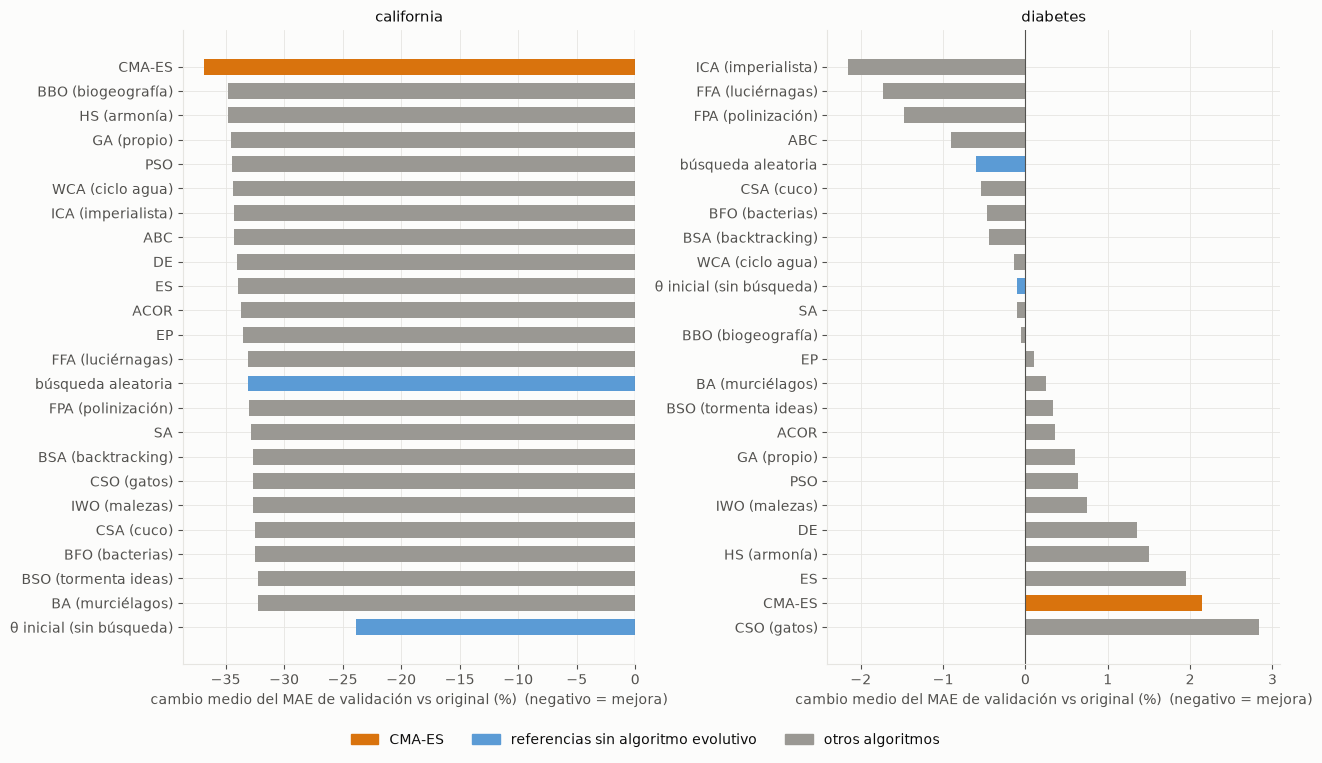

In [16]:
# Figura 3: cambio del MAE de validación (LR+KNN) respecto a los datos originales, por algoritmo
fig, ejes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=False)
for ax, nombre in zip(ejes, ["california", "diabetes"]):
    t = tabla_alg[tabla_alg.dataset == nombre].sort_values("rel LR+KNN", ascending=False)
    colores = [naranja if a == "CMA-ES" else (azules[2] if a in ("búsqueda aleatoria", "θ inicial (sin búsqueda)") else gris) for a in t.algoritmo]
    ax.barh(t.algoritmo, t["rel LR+KNN"], color=colores, height=0.65)
    ax.axvline(0, color=tinta2, lw=0.8)
    ax.set_title(nombre); ax.set_xlabel("cambio medio del MAE de validación vs original (%)  (negativo = mejora)")
fig.legend(handles=[Patch(color=naranja, label="CMA-ES"), Patch(color=azules[2], label="referencias sin algoritmo evolutivo"),
                    Patch(color=gris, label="otros algoritmos")], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**Cómo interpretar la figura.** Cada barra es la media del cambio del MAE de validación (promedio de regresión lineal y KNN) en las dos particiones. Las barras hacia la izquierda son mejoras. Lo que hay que comparar es la **diferencia entre algoritmos**, y hay que mirarla en relación con la que hay entre el punto inicial sin búsqueda y la búsqueda aleatoria (las barras azules), que es lo que se consigue "gratis".

**Qué vemos.**

- **California:** casi todos los algoritmos consiguen entre un 32 % y un 37 % de mejora. Incluso la búsqueda aleatoria logra un 33 %. CMA-ES es el primero por poco (−36.8 %). La diferencia entre los mejores algoritmos es de dos o tres puntos con solo dos particiones, así que no es concluyente. **Lo que importa es la familia de transformaciones, no el algoritmo que la busca.**
- **Diabetes:** ningún algoritmo mejora de forma fiable. Las barras van de −2 % a +3 % y son ruido. CMA-ES tiene el mejor fitness pero en validación empeora KNN. El cuello de botella no es la potencia de búsqueda.
- **Por qué nos quedamos con CMA-ES.** Tiene el mejor rango medio por fitness (2.0, seguido de cerca por el GA propio con 2.5), es de los más baratos en tiempo y está justificado teóricamente para este tipo de problema (continuo, sin gradiente, no separable). No es la única opción razonable y lo decimos así.

### 5.3 ¿Se puede mejorar CMA-ES con un híbrido? (resultado negativo)

Como Diabetes fallaba por sobreajuste al fitness, probamos a diseñar un algoritmo nuevo que mezclara lo mejor de varios. Partimos de CMA-ES y probamos cuatro modificaciones, cada una pensada para un problema concreto:

| Variante | Qué añade | Para qué |
|---|---|---|
| CMA+folds | Cambia los pliegues de validación cruzada en cada generación (el fitness pasa a ser estocástico) | Que la búsqueda no se ajuste a unos pliegues concretos |
| CMA+DE | Inyecta en cada generación un individuo de cruce diferencial (de evolución diferencial) | Más diversidad, algo propio de DE y los algoritmos genéticos |
| CMA+folds+sel | Lo primero más una selección final: reservamos 100 evaluaciones para puntuar los mejores candidatos en pliegues nuevos, y solo aceptamos el aprendido si mejora a $\theta_0$ en más de 0.005 | Elegir de forma robusta |
| Híbrido completo | Pliegues cambiantes, DE y selección final | Todo junto |

Todas con el mismo presupuesto de 1000 evaluaciones, 6 particiones por dataset.

In [17]:
hib = leer("resultados_hibrido.csv")
for m in M3:
    hib["rel " + m] = 100 * (hib[m] / hib["crudo " + m] - 1)
hib["rel LR+KNN"] = (hib["rel Regresión Lineal"] + hib["rel KNN"]) / 2
ordenh = ["CMA-ES (base)", "CMA+DE", "CMA+folds+sel", "Híbrido (folds+DE+sel)", "CMA+folds"]

# Contraste de cada variante frente a CMA-ES base, por dataset (mismas 6 particiones)
filas = []
for nombre in ["diabetes", "california"]:
    q = hib[hib.dataset == nombre].pivot_table(index="semilla", columns="algoritmo", values="rel LR+KNN")
    for v in ordenh[1:]:
        dif = (q[v] - q["CMA-ES (base)"]).values                       # en puntos porcentuales
        filas.append(dict(dataset=nombre, variante=v, dif_media_puntos=round(dif.mean(), 2),
                          mejor_que_base=f"{(dif < 0).sum()}/{len(dif)}", p_wilcoxon=round(wilcoxon(dif).pvalue, 3)))
display(pd.DataFrame(filas))

,dataset,variante,dif_media_puntos,mejor_que_base,p_wilcoxon
0,diabetes,CMA+DE,1.53,3/6,0.438
1,diabetes,CMA+folds+sel,0.98,1/6,0.312
2,diabetes,Híbrido (folds+DE+sel),1.57,0/6,0.031
3,diabetes,CMA+folds,1.24,3/6,0.688
4,california,CMA+DE,-0.28,4/6,0.562
5,california,CMA+folds+sel,0.40,3/6,0.562
6,california,Híbrido (folds+DE+sel),0.30,2/6,0.688
7,california,CMA+folds,7.09,0/6,0.031


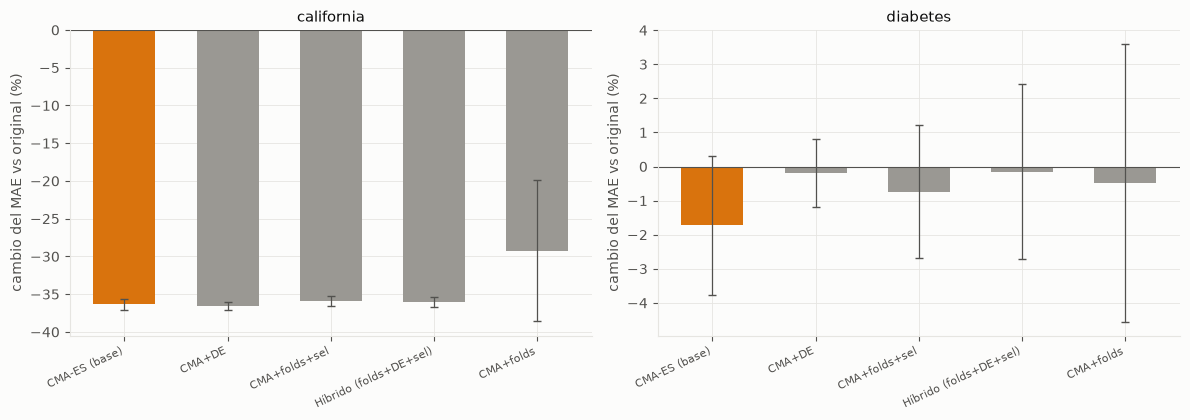

In [18]:
# Figura 4: cambio medio del MAE (LR+KNN) por variante, con la desviación entre particiones
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, nombre in zip(ejes, ["california", "diabetes"]):
    g = hib[hib.dataset == nombre].groupby("algoritmo")["rel LR+KNN"].agg(["mean", "std"]).loc[ordenh]
    ax.bar(range(len(g)), g["mean"], yerr=g["std"], width=0.6,
           color=[naranja if v == "CMA-ES (base)" else gris for v in g.index],
           error_kw=dict(ecolor=tinta2, elinewidth=0.9, capsize=3))
    ax.axhline(0, color=tinta2, lw=0.8)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index, rotation=25, ha="right", fontsize=8)
    ax.set_title(nombre); ax.set_ylabel("cambio del MAE vs original (%)")
fig.tight_layout(); plt.show()

**Cómo interpretar la figura.** La barra es la media en 6 particiones y la línea vertical es la desviación típica entre particiones. Si las líneas de dos variantes se solapan mucho, la diferencia entre ellas no es fiable.

**Qué vemos.**

- **Ninguna variante mejora a CMA-ES base.** En California, DE y la selección robusta no cambian nada (diferencias de décimas de punto). En Diabetes ninguna mejora y el híbrido completo es peor en las 6 particiones.
- **Los pliegues cambiantes empeoran claramente en California** (unos siete puntos peor, y con una dispersión entre particiones unas trece veces mayor). Cada generación compara a los candidatos con un ruido distinto y CMA-ES, que se apoya en ordenar bien a los candidatos de una generación, avanza peor. Nuestra hipótesis de que reduciría el sobreajuste de Diabetes **no se confirmó**.
- **Lección.** Inventar un algoritmo de búsqueda nuevo no tenía recorrido aquí. Lo que movió los resultados fueron la representación y la regla de predicción, no la búsqueda. Por eso el resto de experimentos se centran en eso.

### 5.4 ¿Ayuda meter el PCA dentro de la búsqueda? (reducción de ruido)

La idea era que la propia búsqueda decida qué componentes principales conservar, como una forma de reducir ruido. La representación pasa a ser:

$$ \text{Yeo-Johnson} \rightarrow \text{estandarizar} \rightarrow \text{pesos por atributo} \rightarrow \text{PCA} \rightarrow \text{peso por componente} $$

Con todos los pesos en 1 es una rotación, y las distancias son idénticas a las de la estandarización, de modo que la búsqueda también arranca de la línea base. El peso de cada componente lo aprende CMA-ES: un peso cercano a 0 equivale a descartar ese componente (reducción de ruido aprendida). Añade $n$ parámetros ($3n$ en total). Probamos también una variante con solo dos parámetros (un corte y una suavidad) y la comparamos con el PCA clásico que conserva el 95 % de la varianza.

**Diseño en dos fases para evitar el sesgo de selección.** Una primera tanda (semillas 13 a 15) para elegir la variante, y una **tanda de confirmación con 10 particiones nuevas** (semillas 30 a 39) en la que decidimos antes de mirar que el PCA solo entraría en el método final si mejoraba de forma consistente. Las gráficas usan la tanda de confirmación.

In [19]:
pca = leer("resultados_pca_confirmacion.csv")
orden_pca = ["crudo", "estándar", "CMA-ES (YJ+pesos)", "CMA-ES + PCA (peso por componente)"]
# MAE de KNN (k = 5) relativo al de los atributos originales, por dataset (media en 10 particiones)
p = pca.pivot_table(index="dataset", columns="metodo", values="KNN")[orden_pca]
rel_pca = p.div(p["crudo"], axis=0).loc[DATASETS]
print("Media geométrica del cociente MAE / MAE(original):")
display(np.exp(np.log(rel_pca).mean()).round(3).to_frame("KNN").T)

Media geométrica del cociente MAE / MAE(original):


metodo,crudo,estándar,CMA-ES (YJ+pesos),CMA-ES + PCA (peso por componente)
KNN,1.0,0.871,0.748,0.745


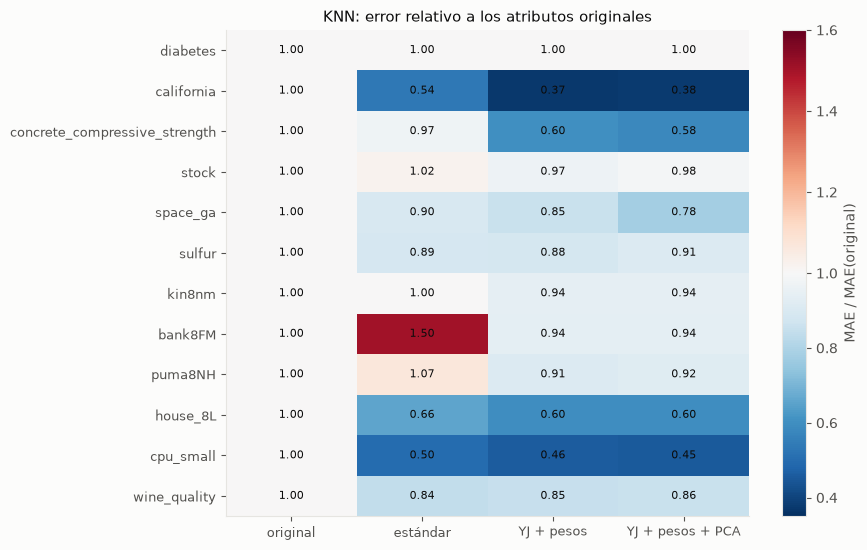

In [20]:
# Figura 5: mapa de calor del cociente MAE / MAE(original) en KNN. Azul = mejora, naranja = empeora
fig, ax = plt.subplots(figsize=(9, 5.6))
im = ax.imshow(rel_pca.values, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=1, vmin=0.35, vmax=1.6), aspect="auto")
ax.set_xticks(range(rel_pca.shape[1])); ax.set_xticklabels(["original", "estándar", "YJ + pesos", "YJ + pesos + PCA"], fontsize=9)
ax.set_yticks(range(rel_pca.shape[0])); ax.set_yticklabels(rel_pca.index, fontsize=9)
for i in range(rel_pca.shape[0]):
    for j in range(rel_pca.shape[1]):
        ax.text(j, i, f"{rel_pca.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color=tinta)
ax.grid(False)
fig.colorbar(im, ax=ax, label="MAE / MAE(original)")
ax.set_title("KNN: error relativo a los atributos originales")
fig.tight_layout(); plt.show()

**Cómo interpretar el mapa de calor.** Cada celda es el cociente entre el error de ese método y el del dataset con los atributos originales. Por debajo de 1 (azul) mejora y por encima de 1 (naranja) empeora. Una **columna** de azules uniformes indica un método que funciona en general, y una **fila** de naranjas indica un dataset difícil.

**Qué vemos.**

- Estandarizar solo mejora en unos datasets y empeora en otros (por ejemplo `bank8FM`, donde sale mucho peor que los datos originales). La columna "YJ + pesos" es mucho más azul que "estándar" y mejora en 11 de 12 datasets.
- Añadir el PCA apenas cambia la columna: se ve casi igual que "YJ + pesos".

Global (120 parejas): -0.44 %, mejor en 57/120, p = 0.975


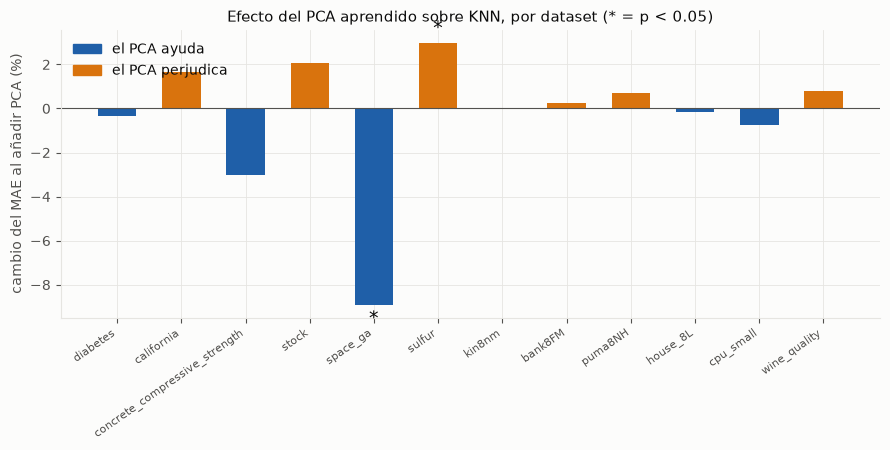

In [21]:
# Contraste global y por dataset: ¿mejora el PCA a la búsqueda sin PCA? (KNN, 10 particiones por dataset)
q = pca.pivot_table(index=["dataset", "semilla"], columns="metodo", values="KNN")
glob = contraste(q, "CMA-ES + PCA (peso por componente)", "CMA-ES (YJ+pesos)")
print(f"Global (120 parejas): {glob['cambio_pct']:+.2f} %, mejor en {glob['mejor_en']}, p = {glob['p_wilcoxon']:.3f}")

filas = []
for nombre in DATASETS:
    c = contraste(q.loc[nombre], "CMA-ES + PCA (peso por componente)", "CMA-ES (YJ+pesos)")
    filas.append(dict(dataset=nombre, **c))
por_dataset = pd.DataFrame(filas).set_index("dataset")

# Figura 6: efecto del PCA en cada dataset (negativo = el PCA ayuda)
fig, ax = plt.subplots(figsize=(9, 4.6))
col = [azules[3] if v < 0 else naranja for v in por_dataset.cambio_pct]
ax.bar(range(len(por_dataset)), por_dataset.cambio_pct, color=col, width=0.6)
for i, (v, p_) in enumerate(zip(por_dataset.cambio_pct, por_dataset.p_wilcoxon)):
    if p_ < 0.05:
        ax.text(i, v + (0.4 if v >= 0 else -0.9), "*", ha="center", fontsize=14)    # asterisco si p < 0.05
ax.axhline(0, color=tinta2, lw=0.8)
ax.set_xticks(range(len(por_dataset))); ax.set_xticklabels(por_dataset.index, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("cambio del MAE al añadir PCA (%)")
ax.set_title("Efecto del PCA aprendido sobre KNN, por dataset (* = p < 0.05)")
ax.legend(handles=[Patch(color=azules[3], label="el PCA ayuda"), Patch(color=naranja, label="el PCA perjudica")], loc="upper left")
fig.tight_layout(); plt.show()

**Cómo interpretar la figura.** Cada barra es el cambio medio del error al añadir PCA, por dataset. Un asterisco indica que ese cambio es estadísticamente distinguible de cero con 10 particiones. Si las barras se reparten a ambos lados, el efecto medio se anula, y eso es lo que pasa aquí.

**Qué vemos.**

- **En conjunto el PCA no aporta**: el cambio global es de aproximadamente −0.4 % y el p-valor es cercano a 1. Con el criterio que habíamos fijado antes, **el PCA se queda fuera del método final**.
- **Ayuda mucho en `space_ga`** (alrededor de un 9 % menos de error, mejor en las 10 particiones). Es un dataset con atributos muy correlacionados, justo donde rotar tiene sentido. **Perjudica en `sulfur`** (cerca de un 3 % más de error) y algo en `stock`. Se compensa.
- **El PCA clásico con corte fijo en el 95 % de varianza empeoró** a la estandarización en la primera tanda (0.896 frente a 0.873 de media). Quitar componentes de forma fija no es la buena forma de reducir el ruido aquí.
- **Una lección de método.** En la primera tanda (3 particiones) el PCA parecía mejorar en los 12 datasets. En la confirmación con particiones nuevas esa ventaja casi desaparece. Es el motivo por el que insistimos en confirmar con particiones que no se usaron para elegir.

### 5.5 Cambiar la regla de predicción: regresión lineal local

Como lo que movió los resultados fue la regla de predicción y no el algoritmo evolutivo, probamos la regla local lineal de la sección 2.5. El experimento separa dos preguntas con cinco configuraciones (6 particiones nuevas en cada uno de los 12 datasets):

| Configuración | Qué responde |
|---|---|
| estándar + KNN y estándar + LLR | ¿Ayuda la regla por sí sola, sin aprender nada? |
| métrica(KNN) + KNN y métrica(KNN) + LLR | Con la misma métrica, ¿ayuda cambiar la regla? |
| métrica(LLR) + LLR | ¿Ayuda optimizar la métrica directamente para la regla? |

En las cuatro primeras $k$ y el ridge se eligen por validación cruzada en una rejilla de 15 combinaciones. En la última los aprende CMA-ES junto con la métrica. Esa última configuración es el **método completo**.

In [22]:
llr_res = leer("resultados_llr.csv")
crudo_knn = pca[pca.metodo == "crudo"][["dataset", "semilla", "KNN"]].rename(columns={"KNN": "crudo"})   # KNN k=5 con atributos originales
llr_res = llr_res.merge(crudo_knn, on=["dataset", "semilla"])
llr_res["rel"] = llr_res.mae / llr_res.crudo
orden_llr = ["estándar + KNN", "estándar + LLR", "métrica(KNN) + KNN", "métrica(KNN) + LLR",
             "métrica(LLR) + LLR (optimizada para la regla)"]
etiquetas = ["estándar\n+ KNN", "estándar\n+ LLR", "métrica(KNN)\n+ KNN", "métrica(KNN)\n+ LLR", "métrica(LLR)\n+ LLR"]
pl = llr_res.pivot_table(index="dataset", columns="metodo", values="rel")[orden_llr].loc[DATASETS]
geom = np.exp(np.log(pl).mean())
display(geom.round(3).to_frame("MAE / MAE(original), media geométrica").T)

metodo,estándar + KNN,estándar + LLR,métrica(KNN) + KNN,métrica(KNN) + LLR,métrica(LLR) + LLR (optimizada para la regla)
"MAE / MAE(original), media geométrica",0.84,0.737,0.724,0.673,0.641


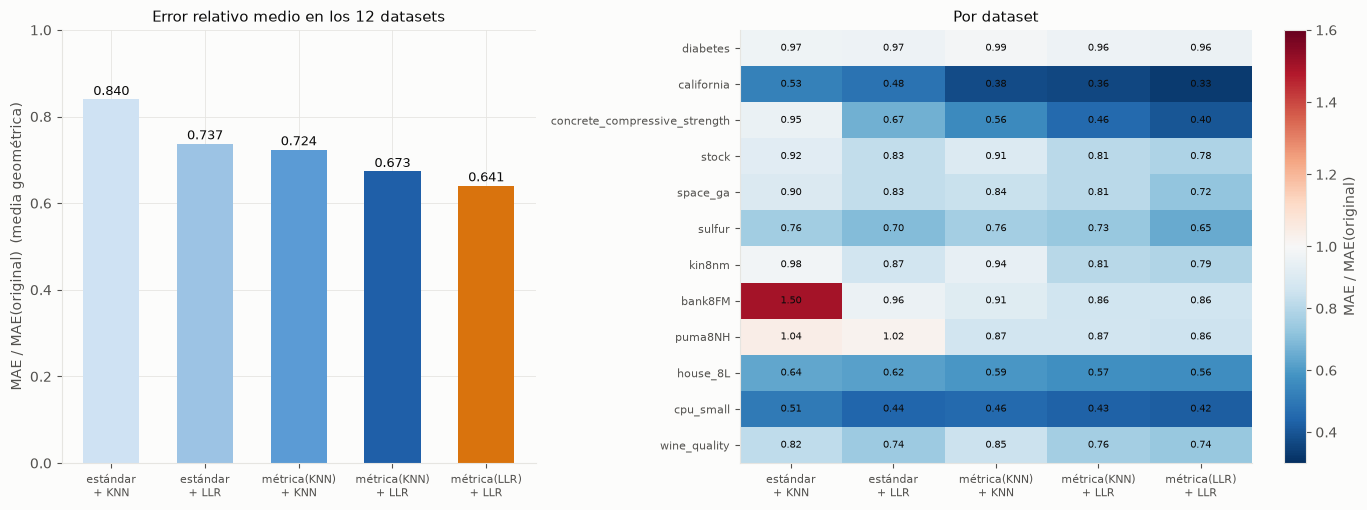

In [23]:
# Figura 7: (izquierda) media geométrica por configuración; (derecha) mapa de calor por dataset
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw=dict(width_ratios=[1, 1.35]))
a1.bar(range(5), geom.values, width=0.6, color=[azules[0], azules[1], azules[2], azules[3], naranja])
for i, v in enumerate(geom.values):
    a1.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
a1.set_xticks(range(5)); a1.set_xticklabels(etiquetas, fontsize=8)
a1.set_ylabel("MAE / MAE(original)  (media geométrica)")
a1.set_title("Error relativo medio en los 12 datasets"); a1.set_ylim(0, 1)
im = a2.imshow(pl.values, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=1, vmin=0.3, vmax=1.6), aspect="auto")
a2.set_xticks(range(5)); a2.set_xticklabels(etiquetas, fontsize=8)
a2.set_yticks(range(len(pl))); a2.set_yticklabels(pl.index, fontsize=8)
for i in range(pl.shape[0]):
    for j in range(5):
        a2.text(j, i, f"{pl.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=tinta)
a2.grid(False); fig.colorbar(im, ax=a2, label="MAE / MAE(original)")
a2.set_title("Por dataset")
fig.tight_layout(); plt.show()

In [24]:
# Contrastes por pares sobre las 72 parejas (12 datasets x 6 particiones)
q = llr_res.pivot_table(index=["dataset", "semilla"], columns="metodo", values="mae")
M = "métrica(LLR) + LLR (optimizada para la regla)"
pares = [("estándar + LLR", "estándar + KNN", "la regla local lineal sola (datos estándar)"),
         ("métrica(KNN) + LLR", "métrica(KNN) + KNN", "cambiar a regla local lineal con la métrica de KNN"),
         (M, "métrica(KNN) + LLR", "optimizar la métrica para la regla frente a reutilizar la de KNN"),
         (M, "estándar + LLR", "método completo frente a la regla local lineal sin aprender"),
         (M, "estándar + KNN", "método completo frente a KNN estándar")]
filas = []
for a, b, texto in pares:
    c = contraste(q, a, b)
    filas.append(dict(comparación=texto, cambio_pct=round(c["cambio_pct"], 1), mejor_en=c["mejor_en"], p_wilcoxon=f"{c['p_wilcoxon']:.4f}"))
display(pd.DataFrame(filas))

,comparación,cambio_pct,mejor_en,p_wilcoxon
0,la regla local lineal sola (datos estándar),-12.1,68/72,0.0000
1,cambiar a regla local lineal con la métrica de...,-6.9,67/72,0.0000
2,optimizar la métrica para la regla frente a re...,-4.9,56/72,0.0000
3,método completo frente a la regla local lineal...,-13.2,66/72,0.0000
4,método completo frente a KNN estándar,-23.7,69/72,0.0000


**Cómo interpretar las figuras y la tabla.** La barra del gráfico de la izquierda es la media geométrica del cociente entre el error del método y el de los datos originales (menor es mejor). El mapa de calor de la derecha desglosa el cociente por dataset. En la tabla, `cambio_pct` es el cambio medio del error entre los dos métodos que se comparan, `mejor_en` cuenta en cuántas de las 72 parejas gana el primero y `p_wilcoxon` es el p-valor del test por pares.

**Qué vemos.**

- **Cada paso mejora al anterior.** La media geométrica baja de 0.84 (estándar + KNN) a 0.64 (método completo). Frente a los datos originales, es un 36 % menos de error.
- **La regla local lineal ayuda por sí sola**: con datos estándar baja el error un 12 % respecto a KNN (gana en 68 de 72 parejas). Una parte de la mejora del método completo viene simplemente de usar una regla más flexible, y no de la métrica.
- **La contribución propia, separada:** frente a la regla local lineal sin aprender, el método completo baja el error un 13 %. Y optimizar la métrica para la regla gana casi un 5 % a reutilizar la métrica de KNN con la regla local lineal, algo pequeño pero consistente (gana en 56 de 72 parejas).
- **Es consistente entre datasets**: el método completo está por debajo de 1 en los 12 datasets. Las mayores mejoras llegan al 60-67 % de reducción del error (`concrete` y `california`), y la menor es la de `diabetes`, de alrededor de un 4 %.

**Dos cautelas.** Primero, la última configuración aprende $k$ y el ridge con 1000 evaluaciones de CMA-ES, mientras que las demás los eligen en una rejilla de 15 combinaciones: parte de la ventaja puede ser simplemente más ajuste de hiperparámetros. Segundo, tarda más (unos 194 s por búsqueda frente a 111 s).

### 5.6 ¿Cómo queda frente a otros modelos? (nivel absoluto)

Que un método mejore a KNN no dice si es bueno en términos absolutos. Lo comparamos con los modelos que suelen ganar en datos tabulares:

- **Random Forest** (200 árboles) y **Gradient Boosting** (HistGradientBoosting), ajustados con una búsqueda aleatoria de 30 configuraciones y validación cruzada de 3 pliegues, y reentrenados con todo el entrenamiento.
- **Proceso gaussiano con ARD** (una escala por atributo, estimada por máxima verosimilitud). Es el competidor teórico más cercano porque aprende justo lo que aprendemos nosotros, pesos por atributo. Lo entrenamos con una submuestra de 2000 filas por coste, lo que le da menos datos que a nuestro método.

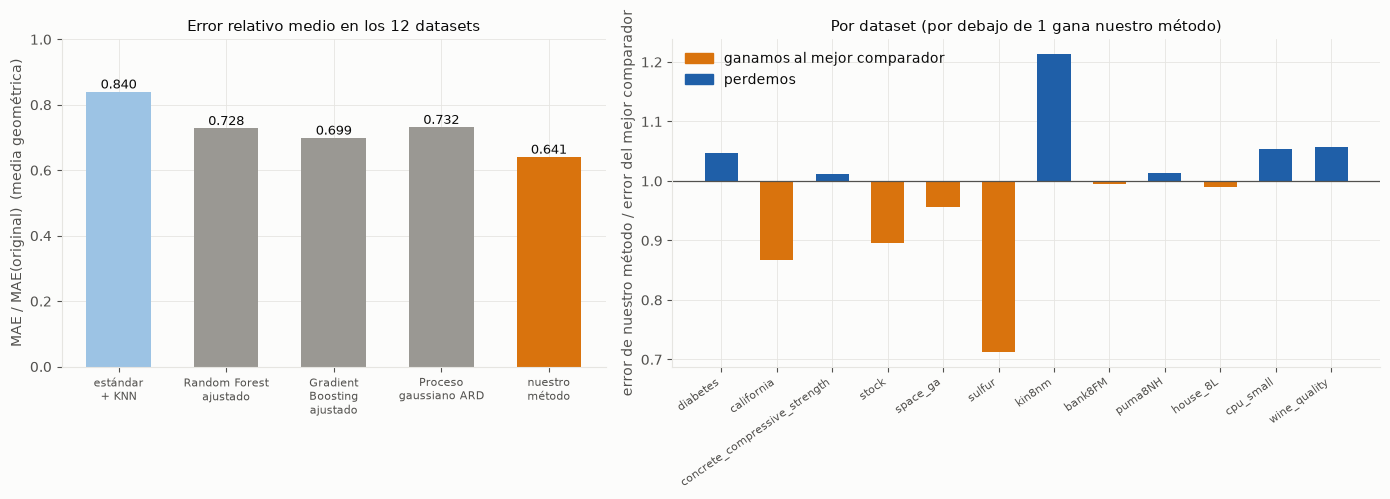

In [25]:
comp = pd.concat([leer("resultados_comparadores.csv"), leer("resultados_ajustados.csv")])
nuestro = llr_res[llr_res.metodo.isin(["estándar + KNN", M])][["dataset", "semilla", "metodo", "mae", "crudo"]]
todo = pd.concat([nuestro, comp.merge(crudo_knn, on=["dataset", "semilla"])[["dataset", "semilla", "metodo", "mae", "crudo"]]])
todo["rel"] = todo.mae / todo.crudo

orden_c = ["estándar + KNN", "Random Forest (ajustado)", "Gradient Boosting (ajustado)", "Proceso gaussiano ARD (n=2000)", M]
nombres_c = ["estándar\n+ KNN", "Random Forest\najustado", "Gradient\nBoosting\najustado", "Proceso\ngaussiano ARD", "nuestro\nmétodo"]
pc = todo.pivot_table(index="dataset", columns="metodo", values="rel")[orden_c].loc[DATASETS]
geom_c = np.exp(np.log(pc).mean())

# Figura 8: media geométrica por modelo y cociente por dataset frente al mejor de los tres comparadores
mdat = todo.groupby(["dataset", "metodo"]).mae.mean().unstack()
mejor_comp = mdat[["Random Forest (ajustado)", "Gradient Boosting (ajustado)", "Proceso gaussiano ARD (n=2000)"]].min(axis=1)
razon = (mdat[M] / mejor_comp).loc[DATASETS]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1, 1.3]))
a1.bar(range(5), geom_c.values, width=0.6, color=[azules[1], gris, gris, gris, naranja])
for i, v in enumerate(geom_c.values):
    a1.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
a1.set_xticks(range(5)); a1.set_xticklabels(nombres_c, fontsize=8)
a1.set_ylabel("MAE / MAE(original)  (media geométrica)"); a1.set_ylim(0, 1)
a1.set_title("Error relativo medio en los 12 datasets")
a2.bar(range(len(razon)), razon.values - 1, bottom=1, width=0.6, color=[naranja if v < 1 else azules[3] for v in razon.values])
a2.axhline(1, color=tinta2, lw=0.9)
a2.set_xticks(range(len(razon))); a2.set_xticklabels(razon.index, rotation=35, ha="right", fontsize=8)
a2.set_ylabel("error de nuestro método / error del mejor comparador")
a2.set_title("Por dataset (por debajo de 1 gana nuestro método)")
a2.legend(handles=[Patch(color=naranja, label="ganamos al mejor comparador"), Patch(color=azules[3], label="perdemos")], loc="upper left")
fig.tight_layout(); plt.show()

In [26]:
# Contrastes por pares sobre las 72 parejas (12 datasets x 6 particiones)
q = todo.pivot_table(index=["dataset", "semilla"], columns="metodo", values="mae")
filas = []
for otro in ["Random Forest (ajustado)", "Gradient Boosting (ajustado)", "Proceso gaussiano ARD (n=2000)"]:
    c = contraste(q, M, otro)
    filas.append(dict(comparación=f"nuestro método frente a {otro}", cambio_pct=round(c["cambio_pct"], 1), mejor_en=c["mejor_en"], p_wilcoxon=f"{c['p_wilcoxon']:.4f}"))
# frente al mejor de los tres elegido en cada pareja, que es la comparación más exigente
q["mejor de los tres"] = q[["Random Forest (ajustado)", "Gradient Boosting (ajustado)", "Proceso gaussiano ARD (n=2000)"]].min(axis=1)
c = contraste(q, M, "mejor de los tres")
filas.append(dict(comparación="nuestro método frente al MEJOR de los tres en cada pareja", cambio_pct=round(c["cambio_pct"], 1), mejor_en=c["mejor_en"], p_wilcoxon=f"{c['p_wilcoxon']:.4f}"))
display(pd.DataFrame(filas))

,comparación,cambio_pct,mejor_en,p_wilcoxon
0,nuestro método frente a Random Forest (ajustado),-12.0,58/72,0.0000
1,nuestro método frente a Gradient Boosting (aju...,-8.3,53/72,0.0000
2,nuestro método frente a Proceso gaussiano ARD ...,-12.4,51/72,0.0000
3,nuestro método frente al MEJOR de los tres en ...,-2.1,33/72,0.6175


**Cómo interpretar las figuras.** A la izquierda, un error relativo menor es mejor. A la derecha, cada barra es el cociente entre el error de nuestro método y el del **mejor** de los tres comparadores en ese dataset: por debajo de 1 (naranja) ganamos y por encima (azul) perdemos. Este cociente es una comparación dura, porque el mejor comparador se elige después de ver los resultados.

**Qué vemos.**

- **De media, nuestro método tiene el menor error** (0.64 frente a 0.70 de Gradient Boosting ajustado, 0.73 de Random Forest ajustado y 0.73 del proceso gaussiano). Frente a cada uno por separado la ventaja es del 8 % al 12 % y significativa.
- **Frente al mejor de los tres en cada pareja la diferencia es de aproximadamente −2 % y no es significativa**. Es decir, **estamos a la altura del mejor modelo de referencia, no por encima**.
- **Por dataset hay ganadores distintos.** Ganamos a los tres en `california`, `sulfur`, `stock` y `space_ga`, y perdemos con claridad en `kin8nm` (el proceso gaussiano es mucho mejor, porque el objetivo es una función muy suave) y algo en `diabetes`, `cpu_small` y `wine_quality`.

**Cautelas.** El proceso gaussiano solo ve 2000 filas, lo que le perjudica en los datasets grandes. Nuestro método ajusta más hiperparámetros (exponentes, pesos, $k$, ridge) que Random Forest y Gradient Boosting, que solo ajustan 30 configuraciones aleatorias. Y la muestra de 12 datasets la elegimos nosotros.

### 5.7 El caso negativo: Diabetes

Diabetes es el único dataset de la práctica donde el método no cumple $e' < e$, y es útil entender por qué. Mostramos el cambio del error por partición para los cuatro métodos de la confirmación (10 particiones).

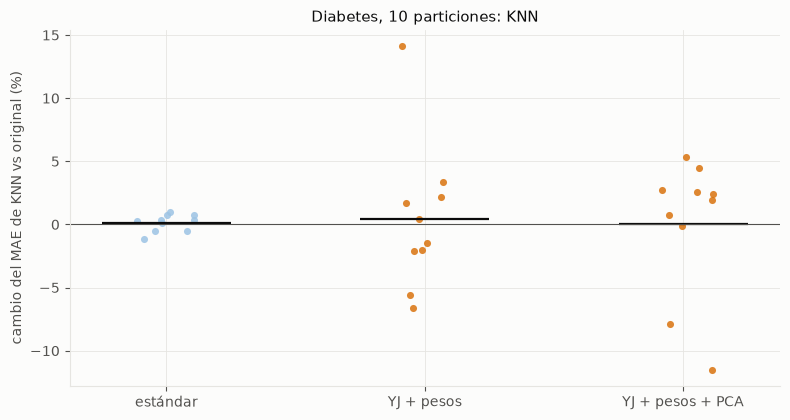

Media y desviación del cambio (%) por método:


,media,desviación
metodo,,
estándar,0.13,0.66
CMA-ES (YJ+pesos),0.40,5.80
CMA-ES + PCA (peso por componente),0.07,5.45


In [27]:
# Cambio del MAE de KNN respecto a los atributos originales, por partición, en Diabetes
d = pca[pca.dataset == "diabetes"].pivot_table(index="semilla", columns="metodo", values="KNN")[orden_pca]
cambio = 100 * (d.div(d["crudo"], axis=0) - 1).drop(columns="crudo")

fig, ax = plt.subplots(figsize=(8, 4.3))
rng = np.random.default_rng(1)
for j, m in enumerate(cambio.columns):
    ax.scatter(j + rng.uniform(-0.12, 0.12, len(cambio)), cambio[m], s=26, color=[azules[1], naranja, naranja][j], alpha=0.85, linewidths=0)
    ax.hlines(cambio[m].mean(), j - 0.25, j + 0.25, color=tinta, lw=1.6)
ax.axhline(0, color=tinta2, lw=0.8)
ax.set_xticks(range(3)); ax.set_xticklabels(["estándar", "YJ + pesos", "YJ + pesos + PCA"])
ax.set_ylabel("cambio del MAE de KNN vs original (%)"); ax.set_title("Diabetes, 10 particiones: KNN")
fig.tight_layout(); plt.show()
print("Media y desviación del cambio (%) por método:")
display(pd.DataFrame({"media": cambio.mean().round(2), "desviación": cambio.std().round(2)}))

**Cómo interpretar la figura.** Es la misma lectura que en la sección 5.0: si los puntos están repartidos a ambos lados del cero y la media está cerca de él, no hay mejora demostrable.

**Qué vemos y por qué pasa.**

- Con 10 particiones nuevas el cambio medio es prácticamente cero para todos los métodos, con una desviación de unos 5 a 6 puntos porcentuales entre particiones. **No hay mejora en Diabetes**, y es la conclusión que tenemos que dar.
- **Causa probable: pocos datos.** Solo hay 309 muestras de entrenamiento para ajustar 20 parámetros con un fitness que usa validación cruzada sobre esas mismas muestras. La búsqueda mejora el fitness (baja un 5-8 %), pero esa mejora no se traslada a validación: es sobreajuste al criterio de búsqueda.
- **Lo que probamos para arreglarlo y no funcionó:** regularizar hacia $\theta_0$, usar un único exponente compartido, pliegues cambiantes y selección robusta con validación independiente. Ninguno mejoró Diabetes de forma consistente.
- **Los propios datos explican que el margen sea bajo.** Los atributos de Diabetes ya vienen centrados y en escalas parecidas, así que estandarizar casi no cambia nada, y no hay colas largas que corregir.
- **Una lección de método.** En una tanda con solo 2 particiones, CMA-ES salía con +2.2 % en Diabetes, y con 6 particiones con −1.7 % (en ambos casos, promedio de regresión lineal y KNN). El signo cambiaba con el número de particiones. Con una desviación de 5 a 6 puntos, **cualquier conclusión sobre Diabetes con pocas particiones es ruido**.

## 6. Análisis global

### 6.1 Qué hemos aprendido, en orden

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Funciona aprender la transformación con CMA-ES? | Sí, y mucho en California; no en Diabetes | 5.0 (13 particiones) |
| ¿Importa qué algoritmo evolutivo se use? | Poco; CMA-ES es la opción más razonable | 5.2 |
| ¿Mejora un híbrido a CMA-ES (pliegues cambiantes, DE, selección)? | No | 5.3 |
| ¿Ayuda el PCA dentro de la búsqueda? | No de forma consistente (sí en `space_ga`, no en `sulfur`) | 5.4 |
| ¿Generaliza a otros datasets? | Sí: KNN mejora un 25 % de media (11 de 12 datasets) | 5.4 |
| ¿Ayuda una regla local lineal y optimizar la métrica para ella? | Sí: otro 13 % frente a esa regla sin aprender | 5.5 |
| ¿Es competitivo con modelos de referencia? | Sí, a la altura del mejor de ellos, no por encima | 5.6 |
| ¿Y en Diabetes? | No mejora; sobreajuste por pocos datos | 5.7 |

### 6.2 Qué se puede afirmar

1. **Una transformación por atributo (exponente de Yeo-Johnson y peso) aprendida con CMA-ES mejora de forma sustancial a los modelos basados en distancias.** Con 10 particiones nuevas y 12 datasets, KNN reduce su error un 25 % respecto a los atributos originales y un 14 % respecto a estandarizar. Con regresión lineal la mejora es del 6-7 % y con el árbol de decisión es nula, como se espera por su invariancia.
2. **La mejora cumple el criterio del enunciado** ($e' < e$) en la gran mayoría de datasets para KNN y en la mayoría para regresión lineal. **No lo cumple en Diabetes.**
3. **Cambiar la regla de predicción a regresión lineal local y optimizar la métrica para ella da una mejora adicional** sobre usar la métrica de KNN. Es un efecto pequeño pero consistente.
4. **El método es competitivo con Random Forest, Gradient Boosting y procesos gaussianos ARD ajustados.** Su error medio es menor que el de cada uno por separado y comparable al del mejor de ellos en cada caso.

### 6.3 Qué no se puede afirmar

- **Que sea una técnica nueva.** Aprender métricas para KNN, ponderar atributos con CMA-ES y la regresión lineal local están publicados. Lo que no hemos encontrado publicado es la combinación concreta, pero nuestra búsqueda bibliográfica fue limitada.
- **Que el algoritmo evolutivo sea lo que produce la mejora.** La búsqueda aleatoria con el mismo presupuesto ya consigue la mayor parte en California. Lo que importa es la familia de transformaciones y la regla de predicción.
- **Que supere a los modelos de referencia.** Está a su altura, con ganadores distintos según el dataset.
- **Que funcione con pocos datos.** Diabetes lo contradice.

### 6.4 Limitaciones

- **Muestra de datasets.** Doce datasets pequeños o medianos, con atributos numéricos, elegidos por nosotros. No hay datos con muchas dimensiones, atributos categóricos, valores perdidos ni muy ruidosos.
- **Número de particiones.** Entre 2 y 13, según el experimento. Las conclusiones sobre Diabetes necesitan muchas particiones por el ruido, y las primeras tandas (2 a 3 particiones) solo sirvieron para explorar. Por eso confirmamos lo importante con particiones nuevas.
- **Ajuste de hiperparámetros desigual.** Nuestro método ajusta más parámetros que los modelos de referencia, así que parte de la ventaja puede venir de ahí.
- **Coste.** La búsqueda tarda entre 1 y 3 minutos por partición. Para un modelo que se entrena una vez es asumible, pero no para uso interactivo.
- **El fitness depende del modelo objetivo.** Optimizamos para KNN o para la regla local lineal. Una transformación buena para ellos puede perjudicar a otro modelo (la regresión lineal empeoró en `bank8FM`, `stock` y `puma8NH`).
- **Citas.** Las referencias de la sección 7 se localizaron con un buscador general y conviene comprobar los datos bibliográficos antes de citarlas.

### 6.5 Trabajo futuro

- Más datasets y más particiones, incluyendo algunos de tamaño grande y con atributos categóricos.
- Un fitness menos propenso al sobreajuste para datos pequeños (por ejemplo, con validación cruzada repetida cada pocas generaciones, sin cambiar los pliegues dentro de una generación).
- Aprender también la forma del núcleo de la regla local (por ejemplo, la anchura en vez de $k$ fijo) y compararlo con el estándar estadístico de ancho de banda por variable por validación cruzada.
- Una comparación con métricas aprendidas por gradiente (Weinberger y Tesauro) y por optimización convexa (LMNN) sobre los mismos 12 datasets. En una exploración previa con dos datasets, el gradiente fue claramente peor que CMA-ES en California, pero no lo hemos repetido con la rigurosidad del resto.

## 7. Referencias y reproducibilidad

### 7.1 Referencias

Las referencias de abajo se localizaron durante el trabajo. Hay que verificar autores, año y datos de publicación antes de incluirlas en la memoria.

- Fister, I., Yang, X.-S., Fister, I., Brest, J. y Fister, D. (2013). *A brief review of nature-inspired algorithms for optimization.* Es el PDF de referencia que dio la asignatura.
- Hansen, N. y Ostermeier, A. (2001). *Completely derandomized self-adaptation in evolution strategies.* Evolutionary Computation. Y Hansen, N. (2016), *The CMA Evolution Strategy: A Tutorial* (arXiv:1604.00772).
- Auger, A. y Hansen, N. (2005). *A restart CMA evolution strategy with increasing population size.* CEC 2005.
- Yeo, I.-K. y Johnson, R. A. (2000). *A new family of power transformations to improve normality or symmetry.* Biometrika.
- Weinberger, K. Q. y Tesauro, G. (2007). *Metric learning for kernel regression.* AISTATS (PMLR 2, 612-619).
- Weinberger, K. Q. y Saul, L. K. (2009). *Distance metric learning for large margin nearest neighbor classification.* JMLR.
- Atkeson, C. G., Moore, A. W. y Schaal, S. (1997). *Locally weighted learning.* Artificial Intelligence Review.
- Hall, P., Li, Q. y Racine, J. S. (2007). *Nonparametric estimation of regression functions in the presence of irrelevant regressors.* Review of Economics and Statistics, 89(4), 784-789.
- DNNR: *Differential Nearest Neighbors Regression* (2022), arXiv:2205.08434.
- Wang, F. y Sun, J. (2015). *Survey on distance metric learning and dimensionality reduction in data mining.* Data Mining and Knowledge Discovery.
- *Evolutionary Algorithm for Large Margin Nearest Neighbour Regression* (2015, ICCCI) y *Development of a novel feature weighting method using CMA-ES optimization* (2018, IEEE SIU). Se localizaron por título.
- Camacho-Villalón, C. L., Stützle, T. y Dorigo, M. y otros (2023), sobre las críticas a los algoritmos basados en metáforas. Citada de memoria: **hay que comprobarla**.

### 7.2 Cómo reproducir los experimentos

Los experimentos largos están en scripts de la carpeta `exploracion/`. Cada uno escribe un CSV con una fila por (dataset, partición, método). Se ejecutan con el entorno `.venv` del proyecto.

| Sección | Script | CSV |
|---|---|---|
| 5.2 | `correr.py` (usa `lib.py`) | `resultados_algoritmos.csv` |
| 5.3 | `correr_hibrido.py` (usa `hibrido.py`) | `resultados_hibrido.csv` |
| 5.4 | `correr_pca.py` y `correr_pca2.py` (usan `pca_lib.py`) | `resultados_pca.csv`, `resultados_pca_confirmacion.csv` |
| 5.5 | `correr_llr.py` (usa `llr_exp.py`) | `resultados_llr.csv` |
| 5.6 | `correr_comp.py` y `correr_aj.py` (usan `comparadores.py` y `ajustados.py`) | `resultados_comparadores.csv`, `resultados_ajustados.csv` |

Los scripts reparten los trabajos en varios procesos (`joblib`) y fijan los hilos de NumPy a uno por proceso. Sus semillas están en el propio script (13 a 18 en las primeras tandas, 30 a 39 en la confirmación). Con 18 procesos, cada experimento tardó entre 10 minutos y una hora en un ordenador de escritorio.

La sección 5.0 usa los CSV del notebook principal (`resultados_cmaes.csv`, en la raíz del proyecto). Las versiones usadas están en `requirements.txt`, más `cma` y `mealpy` para la comparación de algoritmos de la sección 5.2.